# Data Preprocessing & Feature Engineering — BankSim

Pipeline day du: data cleaning → temporal split → categorical encoding → feature engineering → SMOTE comparison → export.

**Dataset**: BankSim ~594k records | **Task**: Binary fraud detection (imbalance ~1.2%)

**Downstream models**: LightGBM, XGBoost, BalancedRandomForestClassifier

In [16]:
import pandas as pd
import numpy as np
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score
import lightgbm as lgb
from imblearn.over_sampling import SMOTE, BorderlineSMOTE
from imblearn.combine import SMOTEENN

DATA_RAW = 'D:/AI66A_group_10_Topic_7/src/data/raw/bs140513_032310.csv'
DATA_OUT = 'D:/AI66A_group_10_Topic_7/data/processed'
os.makedirs(DATA_OUT, exist_ok=True)

## Step 1 — Data Cleaning

In [17]:
df = pd.read_csv(DATA_RAW)

# Strip surrounding whitespace and single-quotes from all string columns
str_cols = ['customer', 'age', 'gender', 'zipcodeOri', 'merchant', 'zipMerchant', 'category']
for c in str_cols:
    df[c] = df[c].str.strip().str.strip("'")

# Binary flag: 1 where original age == 'U' (unknown)
df['age_unknown'] = (df['age'] == 'U').astype(int)

# Map 'U' -> '-1' then cast to int
df['age'] = df['age'].replace('U', '-1').astype(int)

# Drop zero-variance features
df.drop(columns=['zipcodeOri', 'zipMerchant'], inplace=True)

In [18]:
print('--- dtypes after cleaning ---')
print(df.dtypes)
print()
print('Missing values per column:', df.isnull().sum().to_dict())
print('age_unknown distribution:', df['age_unknown'].value_counts().to_dict())
print('age unique values:', sorted(df['age'].unique()))

--- dtypes after cleaning ---
step             int64
customer        object
age              int64
gender          object
merchant        object
category        object
amount         float64
fraud            int64
age_unknown      int64
dtype: object

Missing values per column: {'step': 0, 'customer': 0, 'age': 0, 'gender': 0, 'merchant': 0, 'category': 0, 'amount': 0, 'fraud': 0, 'age_unknown': 0}
age_unknown distribution: {0: 593465, 1: 1178}
age unique values: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


## Step 2 — Temporal Train/Test Split

Sort by `step` ascending. First 80% -> `train_df`, last 20% -> `test_df`. No shuffle.

In [19]:
df = df.sort_values('step').reset_index(drop=True)
split_idx = int(len(df) * 0.8)

train_df = df.iloc[:split_idx].reset_index(drop=True)
test_df  = df.iloc[split_idx:].reset_index(drop=True)

print(f'Train : shape={train_df.shape}  fraud_rate={train_df["fraud"].mean():.4%}')
print(f'Test  : shape={test_df.shape}   fraud_rate={test_df["fraud"].mean():.4%}')

Train : shape=(475714, 9)  fraud_rate=1.2444%
Test  : shape=(118929, 9)   fraud_rate=1.0763%


## Step 3 — Categorical Encoding

Fit `LabelEncoder` on **train only**, then transform both sets. Unseen labels in test set -> `-1`.

In [20]:
cat_cols = ['gender', 'category', 'merchant', 'customer']
encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    le.fit(train_df[col])
    classes_map = {v: i for i, v in enumerate(le.classes_)}

    train_df[col] = train_df[col].map(classes_map)
    # unseen labels map to NaN -> fill -1
    test_df[col]  = test_df[col].map(classes_map).fillna(-1).astype(int)
    encoders[col] = le

print('Encoding complete.')
for col in cat_cols:
    n_unseen = (test_df[col] == -1).sum()
    print(f'  {col:12s}: {len(encoders[col].classes_)} train classes | {n_unseen} unseen in test')

Encoding complete.
  gender      : 4 train classes | 0 unseen in test
  category    : 15 train classes | 0 unseen in test
  merchant    : 50 train classes | 0 unseen in test
  customer    : 4112 train classes | 0 unseen in test


## Step 4 — Feature Engineering

`add_features(df, ref_df)` nhan `ref_df=train_df` de tinh tat ca aggregation va risk encoding tu train only, tranh data leakage.

In [21]:
def add_features(df, ref_df):
    """
    Them cac engineered features vao df.
    Tat ca thong ke duoc tinh tu ref_df (= train_df) de tranh leakage.
    """
    df = df.copy()
    train_mean = ref_df['amount'].mean()
    train_std  = ref_df['amount'].std()

    # ------------------------------------------------------------------ Amount
    df['amount_log']    = np.log1p(df['amount'])
    df['amount_zscore'] = (df['amount'] - train_mean) / (train_std + 1e-8)

    # ----------------------------------------- Customer behavioural (ref_df)
    cust_stats = (
        ref_df.groupby('customer')['amount']
        .agg(cust_mean='mean', cust_std='std', cust_max='max', cust_tx_count='count')
        .reset_index()
    )
    cust_stats['cust_std'] = cust_stats['cust_std'].fillna(0)

    df = df.merge(cust_stats, on='customer', how='left')
    df['cust_mean']     = df['cust_mean'].fillna(train_mean)
    df['cust_std']      = df['cust_std'].fillna(train_std)
    df['cust_max']      = df['cust_max'].fillna(df['amount'])
    df['cust_tx_count'] = df['cust_tx_count'].fillna(1).astype(int)

    df['amount_deviation']    = (df['amount'] - df['cust_mean']) / (df['cust_std'] + 1e-8)
    df['amount_to_max_ratio'] = df['amount'] / (df['cust_max'] + 1e-8)

    # -------------------------------------- Risk encoding (ref_df only, no leakage)
    global_fraud_rate = ref_df['fraud'].mean()
    cat_risk   = ref_df.groupby('category')['fraud'].mean()
    merch_risk = ref_df.groupby('merchant')['fraud'].mean()

    df['category_risk'] = df['category'].map(cat_risk).fillna(global_fraud_rate)
    df['merchant_risk'] = df['merchant'].map(merch_risk).fillna(global_fraud_rate)

    # ---------------------------------------- Behavioural flags (chronological)
    df = df.sort_values('step').reset_index(drop=True)

    df['is_new_merchant'] = (
        ~df.groupby('customer')['merchant'].transform(lambda x: x.duplicated())
    ).astype(int)
    df['is_new_category'] = (
        ~df.groupby('customer')['category'].transform(lambda x: x.duplicated())
    ).astype(int)
    df['is_round_amount'] = (df['amount'] % 10 == 0).astype(int)
    df['is_micro_tx']     = (df['amount'] < 1).astype(int)

    # -------------------------------------------------------------------- Time
    df['hour']       = df['step'] % 24
    df['is_night']   = ((df['hour'] >= 23) | (df['hour'] <= 5)).astype(int)
    df['is_weekend'] = (((df['step'] // 24) % 7) >= 5).astype(int)

    # ----------------------------------------------- Demographic deviation
    age_stats = (
        ref_df.groupby('age')['amount']
        .agg(age_group_mean='mean', age_group_std='std')
        .reset_index()
    )
    age_stats['age_group_std'] = age_stats['age_group_std'].fillna(0)

    df = df.merge(age_stats, on='age', how='left')
    df['age_group_mean']      = df['age_group_mean'].fillna(train_mean)
    df['age_group_std']       = df['age_group_std'].fillna(train_std)
    df['age_group_deviation'] = (
        (df['amount'] - df['age_group_mean']) / (df['age_group_std'] + 1e-8)
    )

    return df

In [22]:
train_df_fe = add_features(train_df, ref_df=train_df)
test_df_fe  = add_features(test_df,  ref_df=train_df)

print(f'Columns after FE : {len(train_df_fe.columns)}')
print(f'Train shape      : {train_df_fe.shape}')
print(f'Test  shape      : {test_df_fe.shape}')
print(f'NaN in train     : {train_df_fe.isnull().sum().sum()}')
print(f'NaN in test      : {test_df_fe.isnull().sum().sum()}')

Columns after FE : 29
Train shape      : (475714, 29)
Test  shape      : (118929, 29)
NaN in train     : 0
NaN in test      : 0


## Step 5 — SMOTE Variant Comparison

LightGBM proxy, 3-fold `StratifiedKFold(shuffle=False)`, metric = `average_precision`.

> SMOTEENN co the chay lau tren dataset lon (~475k rows).

In [23]:
feature_cols = [c for c in train_df_fe.columns if c != 'fraud']
X_tr_all = train_df_fe[feature_cols].values
y_tr_all  = train_df_fe['fraud'].values

resamplers = {
    'No resampling':        None,
    'SMOTE(0.1)':           SMOTE(sampling_strategy=0.1, random_state=42),
    'BorderlineSMOTE(0.1)': BorderlineSMOTE(sampling_strategy=0.1, random_state=42),
    'SMOTEENN(0.1)':        SMOTEENN(sampling_strategy=0.1, random_state=42),
}

lgb_params = dict(
    n_estimators=200, learning_rate=0.05, num_leaves=31,
    random_state=42, verbose=-1, n_jobs=-1,
)

cv   = StratifiedKFold(n_splits=3, shuffle=False)
rows = []

for name, resampler in resamplers.items():
    print(f'  {name} ...', flush=True)
    ap_scores, sizes = [], []
    for tr_idx, val_idx in cv.split(X_tr_all, y_tr_all):
        X_cv, y_cv   = X_tr_all[tr_idx], y_tr_all[tr_idx]
        X_val, y_val = X_tr_all[val_idx], y_tr_all[val_idx]
        if resampler is not None:
            X_cv, y_cv = resampler.fit_resample(X_cv, y_cv)
        clf = lgb.LGBMClassifier(**lgb_params)
        clf.fit(X_cv, y_cv)
        ap_scores.append(average_precision_score(y_val, clf.predict_proba(X_val)[:, 1]))
        sizes.append(len(X_cv))
    rows.append({
        'Variant':         name,
        'Mean AUC-PR':     round(float(np.mean(ap_scores)), 4),
        'Std':             round(float(np.std(ap_scores)),  4),
        'Avg Train Size':  int(np.mean(sizes)),
    })

results_df   = pd.DataFrame(rows)
best_variant = results_df.loc[results_df['Mean AUC-PR'].idxmax(), 'Variant']

print()
print(results_df.to_string(index=False))
print(f'\nBest variant: {best_variant}')

  No resampling ...
  SMOTE(0.1) ...
  BorderlineSMOTE(0.1) ...
  SMOTEENN(0.1) ...

             Variant  Mean AUC-PR    Std  Avg Train Size
       No resampling       0.8454 0.0679          317142
          SMOTE(0.1)       0.9112 0.0233          344515
BorderlineSMOTE(0.1)       0.9180 0.0170          344515
       SMOTEENN(0.1)       0.9058 0.0178          339470

Best variant: BorderlineSMOTE(0.1)


In [24]:
X_train = train_df_fe[feature_cols].values
y_train = train_df_fe['fraud'].values
X_test  = test_df_fe[feature_cols].values
y_test  = test_df_fe['fraud'].values

# Re-instantiate resampler to fit on full training set
resampler_map = {
    'SMOTE(0.1)':           SMOTE(sampling_strategy=0.1, random_state=42),
    'BorderlineSMOTE(0.1)': BorderlineSMOTE(sampling_strategy=0.1, random_state=42),
    'SMOTEENN(0.1)':        SMOTEENN(sampling_strategy=0.1, random_state=42),
}

best_resampler = resampler_map.get(best_variant)
if best_resampler is not None:
    X_train_res, y_train_res = best_resampler.fit_resample(X_train, y_train)
else:
    X_train_res, y_train_res = X_train.copy(), y_train.copy()

print(f'X_train_res : {X_train_res.shape}   fraud rate: {y_train_res.mean():.4%}')

X_train_res : (516773, 28)   fraud rate: 9.0908%


## Step 6 — Export

Luu tat ca artifacts vao `data/processed/` de dung trong training notebook.

In [25]:
export_map = {
    'X_train':      X_train,
    'X_test':       X_test,
    'y_train':      y_train,
    'y_test':       y_test,
    'X_train_res':  X_train_res,
    'y_train_res':  y_train_res,
    'encoders':     encoders,
    'feature_cols': feature_cols,
}

for name, obj in export_map.items():
    joblib.dump(obj, os.path.join(DATA_OUT, f'{name}.pkl'))

print('Saved to:', DATA_OUT)
for name in export_map:
    kb = os.path.getsize(os.path.join(DATA_OUT, f'{name}.pkl')) / 1024
    print(f'  {name}.pkl  ({kb:.0f} KB)')

Saved to: D:/AI66A_group_10_Topic_7/data/processed
  X_train.pkl  (104063 KB)
  X_test.pkl  (26016 KB)
  y_train.pkl  (3717 KB)
  y_test.pkl  (929 KB)
  X_train_res.pkl  (113044 KB)
  y_train_res.pkl  (4038 KB)
  encoders.pkl  (84 KB)
  feature_cols.pkl  (0 KB)


In [26]:
print('=== Feature List ===')
for i, col in enumerate(feature_cols, 1):
    print(f'  {i:2d}. {col}')
print(f'\nX_train_res shape : {X_train_res.shape}')
print(f'X_test shape      : {X_test.shape}')

=== Feature List ===
   1. step
   2. customer
   3. age
   4. gender
   5. merchant
   6. category
   7. amount
   8. age_unknown
   9. amount_log
  10. amount_zscore
  11. cust_mean
  12. cust_std
  13. cust_max
  14. cust_tx_count
  15. amount_deviation
  16. amount_to_max_ratio
  17. category_risk
  18. merchant_risk
  19. is_new_merchant
  20. is_new_category
  21. is_round_amount
  22. is_micro_tx
  23. hour
  24. is_night
  25. is_weekend
  26. age_group_mean
  27. age_group_std
  28. age_group_deviation

X_train_res shape : (516773, 28)
X_test shape      : (118929, 28)


## SHAP test

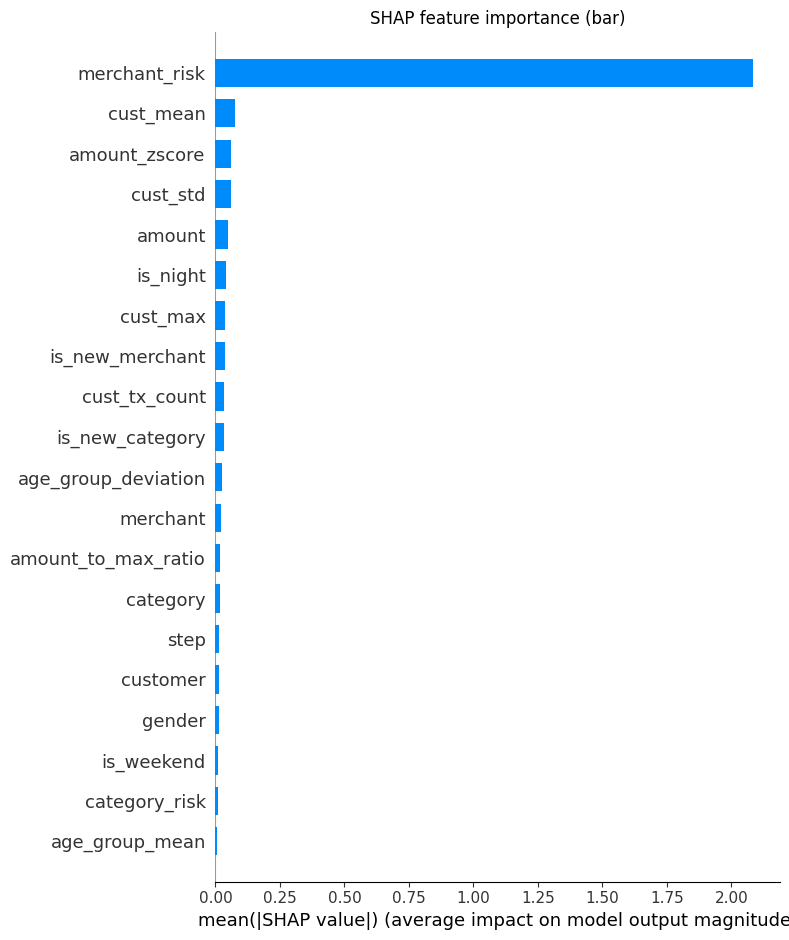

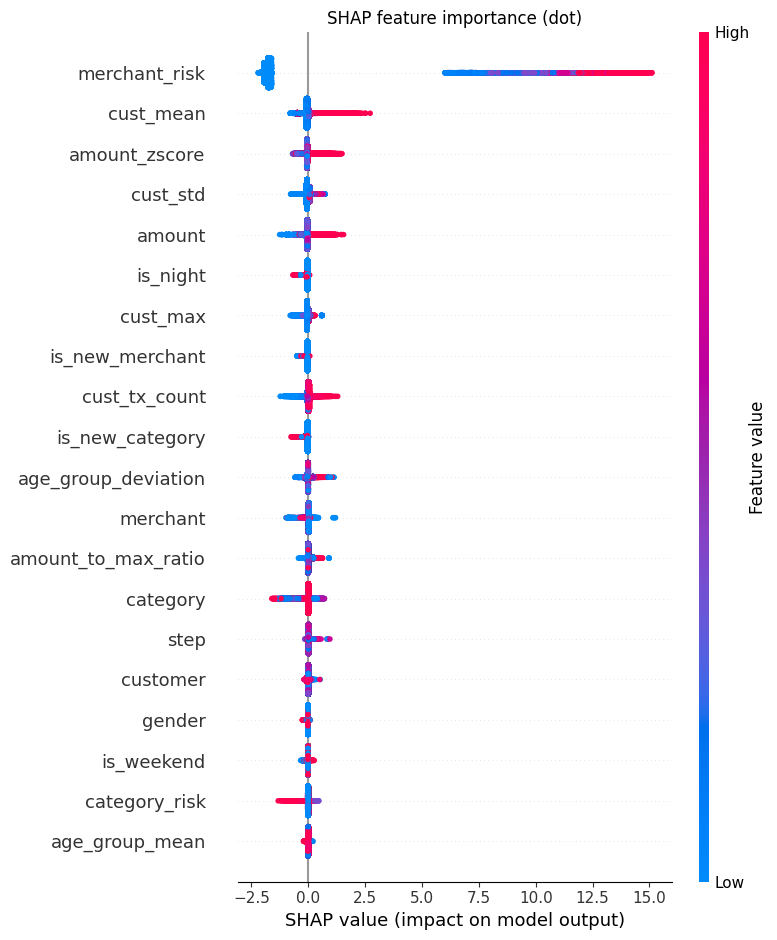

Top 15 SHAP features:
            feature  mean_abs_shap
      merchant_risk       2.084631
          cust_mean       0.075664
      amount_zscore       0.061472
           cust_std       0.059391
             amount       0.046933
           is_night       0.042540
           cust_max       0.038834
    is_new_merchant       0.035664
      cust_tx_count       0.033183
    is_new_category       0.032473
age_group_deviation       0.023532
           merchant       0.022999
amount_to_max_ratio       0.019373
           category       0.017677
               step       0.015571


In [29]:
import shap
import matplotlib.pyplot as plt

# 1) train model final (chọn best_resampler đã dùng)
model = lgb.LGBMClassifier(
    n_estimators=200, learning_rate=0.05, num_leaves=31,
    random_state=42, verbose=-1, n_jobs=-1
)
model.fit(X_train_res, y_train_res)

# 2) SHAP explainer (LightGBM tree explainer)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)  # [0]: neg, [1]: pos; binary
shap_vals_pos = shap_values[1] if isinstance(shap_values, list) else shap_values

# 3) summary plot
shap.summary_plot(shap_vals_pos, X_test, feature_names=feature_cols, plot_type='bar', show=False)
plt.title('SHAP feature importance (bar)')
plt.tight_layout()
plt.show()

shap.summary_plot(shap_vals_pos, X_test, feature_names=feature_cols, show=False)
plt.title('SHAP feature importance (dot)')
plt.tight_layout()
plt.show()

# 4) top-k features (mean abs SHAP)
mean_abs_shap = np.abs(shap_vals_pos).mean(axis=0)
shap_rank = pd.DataFrame({'feature': feature_cols, 'mean_abs_shap': mean_abs_shap})
shap_rank = shap_rank.sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)
print('Top 15 SHAP features:')
print(shap_rank.head(15).to_string(index=False))

In [33]:
# ...existing code...

import pandas as pd
from sklearn.metrics import average_precision_score

# Dùng cùng feature_cols đã xác định trong notebook
X_train_res_df = pd.DataFrame(X_train_res, columns=feature_cols)
X_test_df      = pd.DataFrame(X_test, columns=feature_cols)

if 'merchant_risk' not in feature_cols:
    raise ValueError("merchant_risk không nằm trong feature_cols")

baseline_cols = feature_cols
no_merchant_cols = [c for c in feature_cols if c != 'merchant_risk']

def auc_pr_for_cols(cols):
    model_temp = lgb.LGBMClassifier(
        n_estimators=200, learning_rate=0.05, num_leaves=31,
        random_state=42, verbose=-1, n_jobs=-1
    )
    model_temp.fit(X_train_res_df[cols], y_train_res)
    y_proba = model_temp.predict_proba(X_test_df[cols])[:, 1]
    return average_precision_score(y_test, y_proba)

auc_with = auc_pr_for_cols(baseline_cols)
auc_without = auc_pr_for_cols(no_merchant_cols)

print(f"AUC-PR with merchant_risk   : {auc_with:.4f}")
print(f"AUC-PR without merchant_risk: {auc_without:.4f}")
print(f"Delta (with - without)      : {auc_with - auc_without:.4f}")

AUC-PR with merchant_risk   : 0.9321
AUC-PR without merchant_risk: 0.9185
Delta (with - without)      : 0.0137


In [37]:

# filepath: d:\AI66A_group_10_Topic_7\notebooks\Feature_engineering\Data_Preprocessing_FE.ipynb
import joblib
import pandas as pd

X_train_res = joblib.load(r'D:\AI66A_group_10_Topic_7\data\processed\X_train_res.pkl')

# Nếu X_train_res là array, chuyển sang DataFrame để debug inspect
X_train_res_df = pd.DataFrame(X_train_res, columns=feature_cols)

# Preview cơ bản
display(X_train_res_df.head())      # trong notebook
print("shape:", X_train_res_df.shape)
print("dtypes:\n", X_train_res_df.dtypes)
print(X_train_res_df.describe())

,step,customer,age,gender,merchant,category,amount,age_unknown,amount_log,amount_zscore,...,is_new_merchant,is_new_category,is_round_amount,is_micro_tx,hour,is_night,is_weekend,age_group_mean,age_group_std,age_group_deviation
0,0.0,2264.0,3.0,2.0,18.0,12.0,4.23,0.0,1.654411,-0.297519,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,38.303670,113.034329,-0.301445
1,0.0,2340.0,2.0,2.0,30.0,12.0,11.23,0.0,2.503892,-0.236054,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,38.511611,123.126405,-0.221574
2,0.0,2630.0,2.0,1.0,18.0,12.0,62.11,0.0,4.144879,0.210708,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,38.511611,123.126405,0.191660
3,0.0,2176.0,2.0,1.0,30.0,12.0,15.84,0.0,2.823757,-0.195575,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,38.511611,123.126405,-0.184133
4,0.0,1925.0,3.0,2.0,30.0,12.0,31.45,0.0,3.479700,-0.058508,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,38.303670,113.034329,-0.060634


shape: (516773, 28)
dtypes:
 step                   float64
customer               float64
age                    float64
gender                 float64
merchant               float64
category               float64
amount                 float64
age_unknown            float64
amount_log             float64
amount_zscore          float64
cust_mean              float64
cust_std               float64
cust_max               float64
cust_tx_count          float64
amount_deviation       float64
amount_to_max_ratio    float64
category_risk          float64
merchant_risk          float64
is_new_merchant        float64
is_new_category        float64
is_round_amount        float64
is_micro_tx            float64
hour                   float64
is_night               float64
is_weekend             float64
age_group_mean         float64
age_group_std          float64
age_group_deviation    float64
dtype: object
                step       customer            age         gender  \
count  516773.000000